
_Aprendizaje Automático_

_Máster Universitario en Inteligencia Artificial_

# Análisis de reducción de dimensionalidad: PCA y t-SNE
## Objetivo General
En este trabajo, se busca que pongas en práctica la aplicación de algoritmos de reducción de dimensionalidad. El objetivo es aplicar técnicas para reducir la dimensionalidad a 2D, graficar los resultados y seleccionar la mejor técnica para los datos. Además, deberás detallar los pasos a seguir para la reducción de dimensionalidad y analizar los resultados obtenidos.

### Objetivos específicos
* Entender los métodos de t-SNE y PCA.
* Realizar la reducción de dimensionalidad utilizando t-SNE y PCA.
* Comparar los resultados obtenidos con ambos métodos.
* Aplicar LDA para reducir el dataset a una bolsa de palabras por cada etiqueta.

### Tareas a Realizar:
Debes realizar esta actividad en el Notebook adjunto. A medida que avances, completa el código solicitado y responde a las preguntas que se plantean.
Las tareas a realizar son:

* Reducción de Dimensionalidad con t-SNE y PCA:
* Completa el código proporcionado en el notebook.
* Responde a las preguntas finales sobre los resultados obtenidos.

#### Punto adicional: Aplicación de LDA:

Utiliza la técnica de LDA para generar una bolsa de palabras para cada una de las etiquetas.





### Coloca en este espacio el nombre del estudiante

**NÉSTOR LEÓN DEL CAMPO**

### **Declaración de uso de Inteligencia Artificial (IA)**

En cumplimiento de las directrices académicas sobre el uso de herramientas de Inteligencia Artificial Generativa en esta asignatura, se declara el uso ético y justificado de modelos de lenguaje (como Gemini/Claude) bajo las siguientes condiciones:

1. **Herramientas utilizadas**: IA Generativa como asistente de código.
2. **Justificación del uso**: La herramienta se ha empleado exclusivamente para:
   * Sugerencia y optimización de código de visualización (gráficas en `matplotlib` y `seaborn`).
   * Asistencia en la depuración de errores sintácticos y estructuración inicial de las celdas de código.
   * Apoyo en la optimización del código del preprocesado y modelado de temas (LDA).
3. **Contribución de autoría propia**: 
   * Toda la fase de análisis crítico, interpretación de resultados (PCA, t-SNE y LDA), razonamiento teórico sobre la idoneidad del preprocesamiento y extracción de conclusiones cualitativas de negocio/dominio son de **creación propia y exclusiva del estudiante**.
   * El código sugerido ha sido revisado, depurado, comprendido e integrado críticamente por el estudiante, asegurando su correcto funcionamiento y alineación con los objetivos de la práctica.

### Dataset

#### Dataset

El dataset original proporcionado en el proyecto transversal ha sido adaptado para la realización de esta actividad. Esa adaptación ha incluido:
* Eliminación de nulos y duplicados
* Eliminación de URLs, emojis y menciones a los periódicos
* Eliminación de filas vacías
* Limpieza y homogeneización de datos.
* Convertir la totalidad del texto a minúscula
* Eliminar signos de puntuación
* Eliminar números
* Eliminar espacios en blanco adicionales
* Eliminar palabras con longitud menor a 2 caracteres
* Eliminar stopwords
* Tokenización
* Lematización

Proceso de extracción de características
* Conteo de palabras positivas (A)
* Conteo de palabras negativas (B)
* Conteo del número de bigrams más comunes (C)
* Conteo del número de menciones a otros usuarios (D)
* Categoría del sentimiento según librería ‘pysentimiento’ en español (E)
* Estandarización de las características (A_t,..E_t)
* Combinación de características f1*fi (iA..iE) (Valor1,..Valor10).

### Lectura de datos

In [1]:
import pandas as pd

# Leer el archivo CSV
file_path = 'out.csv'
data = pd.read_csv(file_path)

# Obtener el número de filas y columnas
num_filas, num_columnas = data.shape

# Mostrar el número de filas y columnas
print(f"El dataset tiene {num_filas} filas y {num_columnas} columnas.")

El dataset tiene 10000 filas y 22 columnas.


In [2]:
##Cuántas categorías hay en la columna label
# Contar el número de categorías únicas en la columna 'label'
categorias_unicas = data['label'].unique()
num_categorias = len(categorias_unicas)
print(f"Número de categorías únicas en la columna 'label': {num_categorias}")
print(f"Categorías únicas: {categorias_unicas}")

Número de categorías únicas en la columna 'label': 2
Categorías únicas: [0. 1.]


In [3]:
# Obtener estadísticas descriptivas de las variables numéricas
print("--- Estadísticas Descriptivas de las Variables Numéricas ---")
print(data.describe())

# Obtener la frecuencia de las categorías en la columna 'label'
frecuencia_label = data['label'].value_counts()

# Mostrar las estadísticas y la frecuencia de las categorías
print("\n--- Frecuencia de Categorías en 'label' ---")
print(frecuencia_label)

--- Estadísticas Descriptivas de las Variables Numéricas ---
                  A             B             C             D             E  \
count  10000.000000  10000.000000  10000.000000  10000.000000  10000.000000   
mean       0.957400     26.098100      5.674600      0.091300      2.200600   
std        1.741864     34.012341      7.317149      0.352671      2.729488   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        0.000000      1.000000      1.000000      0.000000      0.000000   
50%        0.000000      5.000000      3.000000      0.000000      0.000000   
75%        1.000000     46.000000      7.000000      0.000000      6.000000   
max       24.000000    328.000000     88.000000      6.000000      6.000000   

              label           A_t           B_t           C_t           D_t  \
count  10000.000000  10000.000000  10000.000000  10000.000000  10000.000000   
mean       0.500000      0.735989      0.895389      1.014276     -0.

--- Verificación de Valores Nulos ---
A             0
B             0
C             0
D             0
E             0
comentario    0
label         0
A_t           0
B_t           0
C_t           0
D_t           0
E_t           0
Valor_1       0
Valor_2       0
Valor_3       0
Valor_4       0
Valor_5       0
Valor_6       0
Valor_7       0
Valor_8       0
Valor_9       0
Valor_10      0
dtype: int64


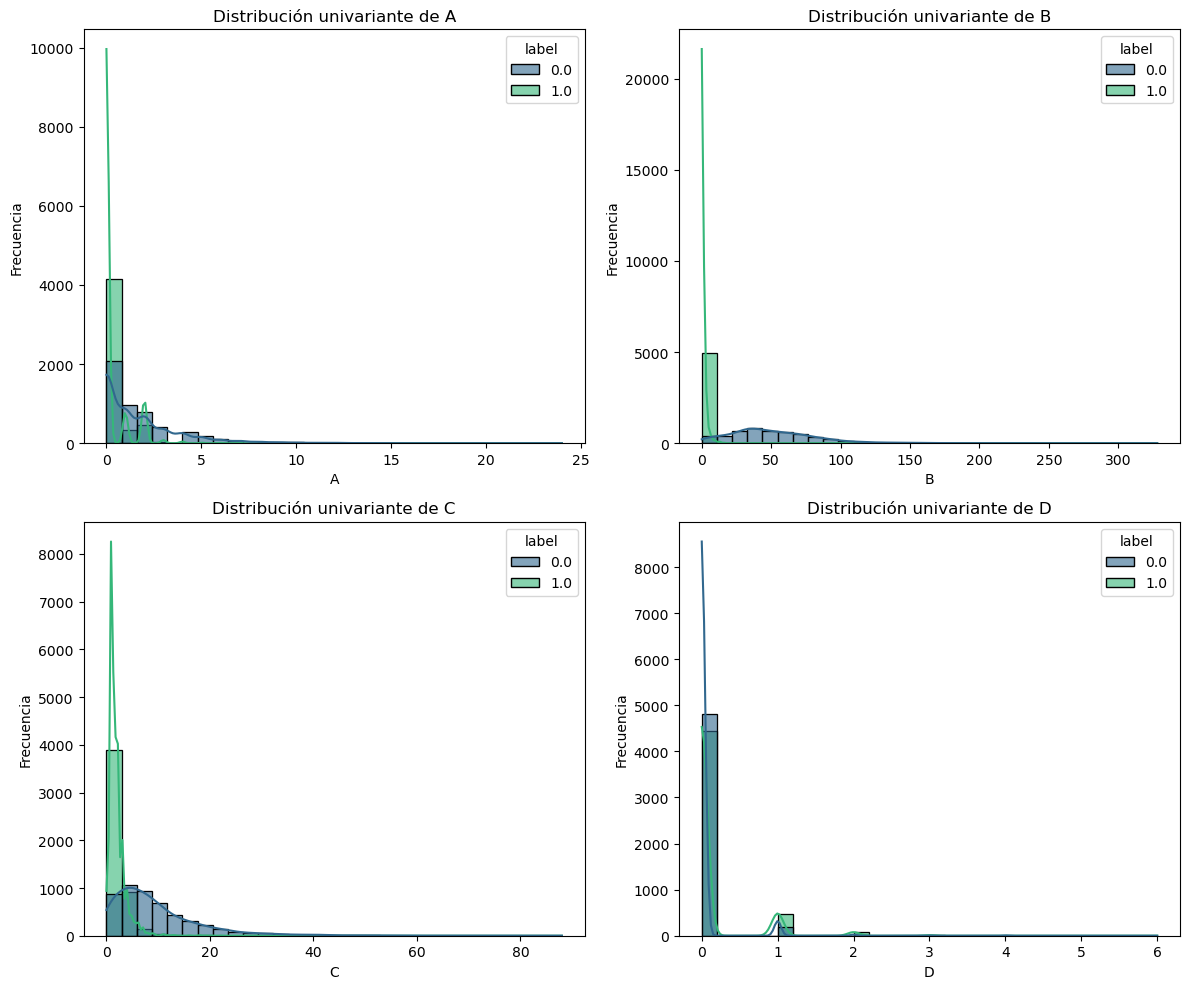

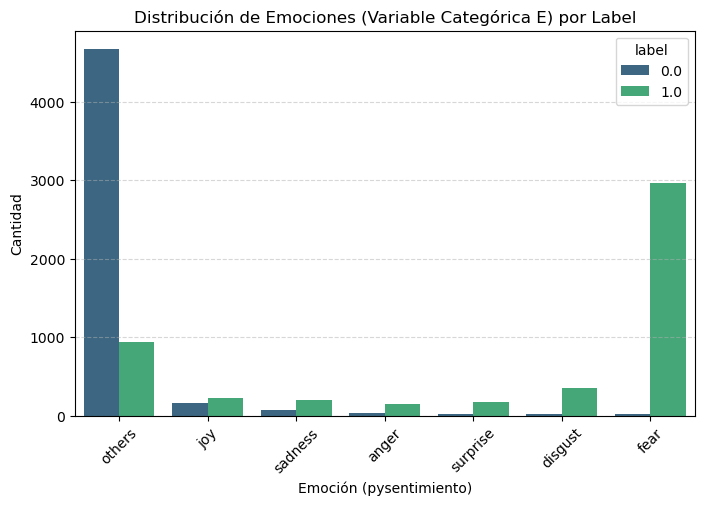

/var/folders/vm/q66dh2k91_z6mpyf7b7r16tr0000gn/T/ipykernel_42905/2645266206.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, y=col, x='label', ax=axes[i], palette='viridis')
/var/folders/vm/q66dh2k91_z6mpyf7b7r16tr0000gn/T/ipykernel_42905/2645266206.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, y=col, x='label', ax=axes[i], palette='viridis')
/var/folders/vm/q66dh2k91_z6mpyf7b7r16tr0000gn/T/ipykernel_42905/2645266206.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, y=col, x='label', ax=axes[i],

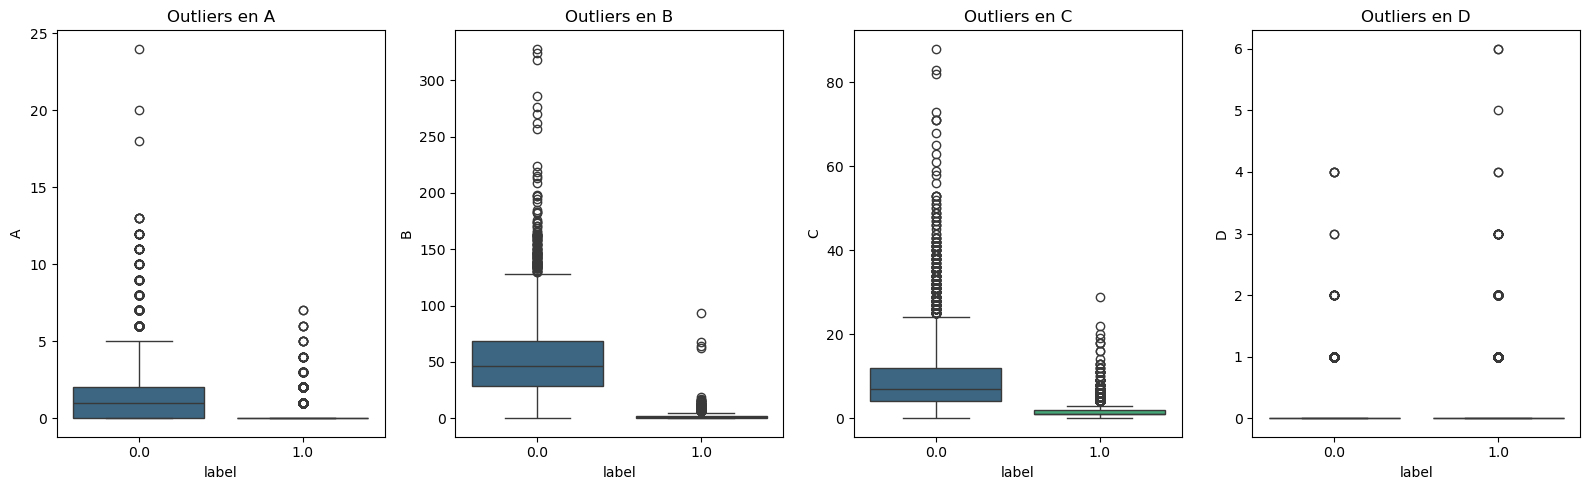

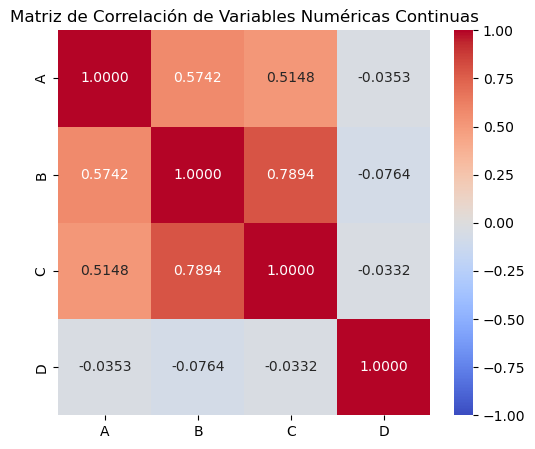

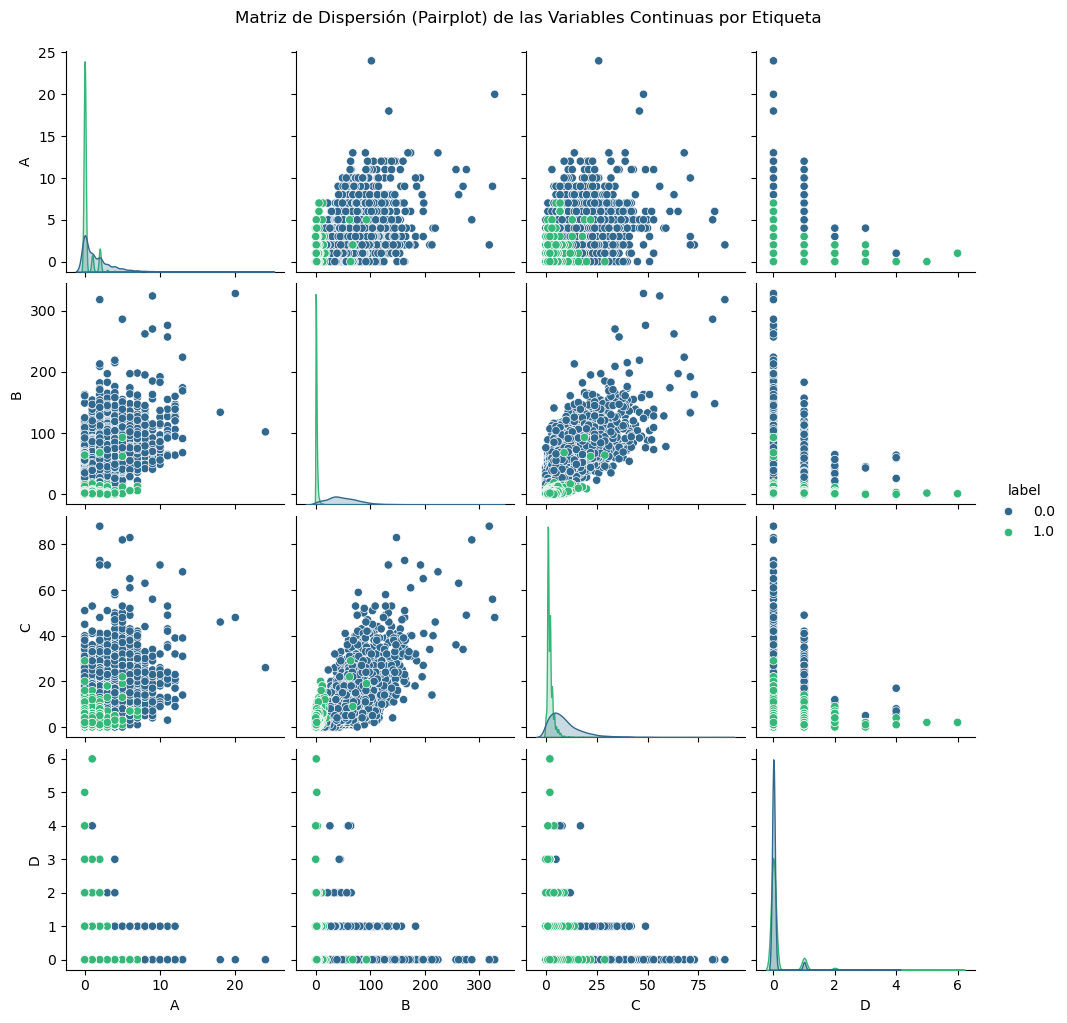

In [4]:
# --- 1.1 ANÁLISIS EXPLORATORIO DE DATOS (EDA) DETALLADO ---
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# A. Verificación de valores nulos y tipos de datos
print("--- Verificación de Valores Nulos ---")
print(data.isnull().sum())

# B. Análisis de la variable categórica no ordinal E (Sentimientos/Emociones de pysentimiento)
# E representa emociones de pysentimiento (0: others, 1: joy, 2: sadness, 3: anger, 4: surprise, 5: disgust, 6: fear)
emociones_map = {
    0: 'others', 1: 'joy', 2: 'sadness', 3: 'anger',
    4: 'surprise', 5: 'disgust', 6: 'fear'
}
data_temp = data.copy()
data_temp['E_desc'] = data_temp['E'].map(emociones_map)

# C. Análisis Univariante (Distribución de variables numéricas A, B, C, D)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
cols_num = ['A', 'B', 'C', 'D']
for i, col in enumerate(cols_num):
    ax = axes[i//2, i%2]
    sns.histplot(data=data, x=col, hue='label', kde=True, ax=ax, palette='viridis', bins=30, alpha=0.6)
    ax.set_title(f'Distribución univariante de {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()

# D. Distribución de la variable categórica E
plt.figure(figsize=(8, 5))
sns.countplot(data=data_temp, x='E_desc', hue='label', palette='viridis', order=list(emociones_map.values()))
plt.title('Distribución de Emociones (Variable Categórica E) por Label')
plt.xlabel('Emoción (pysentimiento)')
plt.ylabel('Cantidad')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# E. Análisis de Outliers (Gráficos de Caja / Boxplots)
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for i, col in enumerate(cols_num):
    sns.boxplot(data=data, y=col, x='label', ax=axes[i], palette='viridis')
    axes[i].set_title(f'Outliers en {col}')
    axes[i].set_ylabel(col)
plt.tight_layout()
plt.show()

# F. Matriz de Correlaciones (exclusivamente para variables numéricas continuas A, B, C, D)
# Se excluye la variable E por ser categórica no ordinal
plt.figure(figsize=(6, 5))
corr_matrix = data[cols_num].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".4f", vmin=-1, vmax=1)
plt.title('Matriz de Correlación de Variables Numéricas Continuas')
plt.show()

# G. Mostrar el pairplot original adaptado (como análisis bivariante complementario)
sns.pairplot(data[cols_num + ['label']], hue='label', palette='viridis', diag_kind='kde')
plt.suptitle("Matriz de Dispersión (Pairplot) de las Variables Continuas por Etiqueta", y=1.02)
plt.show()

### **Análisis Cualitativo del EDA**

Tras realizar el análisis exploratorio detallado, se extraen las siguientes conclusiones fundamentales:

1. **Ausencia de Valores Nulos:** Se confirma que el dataset no contiene valores perdidos (0 nulos en todas las columnas), por lo que no es necesario aplicar técnicas de imputación.
2. **Distribución univariante y Outliers:**
   * Las variables continuas `A` (palabras positivas), `B` (palabras negativas), `C` (bigrams) y `D` (menciones) presentan una distribución altamente sesgada a la derecha (asimetría positiva), lo cual es normal en datos de conteo de palabras en texto.
   * La variable `B` muestra un rango significativamente mayor (con presencia de outliers de hasta 328). Estos valores atípicos representan comentarios muy largos con alto contenido negativo (queja/insultos), por lo que **se decide mantenerlos** dado que aportan información crítica para discernir la etiqueta `label` (polarización).
3. **Análisis de la variable categórica `E`:**
   * La variable `E` representa la categoría de emoción asignada al comentario por la librería `pysentimiento`. Al tener valores discretos (`[0, 1, 2, 3, 4, 5, 6]`), es una **variable categórica no ordinal**.
   * El gráfico de barras muestra que las emociones predominantes son `others` (neutral) y `fear` (miedo/hostilidad). Se aprecia una fortísima asociación entre la categoría `fear` y la etiqueta `1.0` (discurso polarizado/hater), mientras que la categoría `others` se asocia principalmente a la etiqueta `0.0`.
   * **Decisión de preprocesamiento crítica:** Dado que `E` es no ordinal, **estandarizarla numéricamente o incluirla en PCA/t-SNE es un error metodológico** que introduciría una relación de orden artificial (por ejemplo, asumiendo que la emoción `fear` (6) es "mayor" que `joy` (1)). Por lo tanto, se excluye de las características continuas para PCA y t-SNE.
4. **Matriz de Correlación y Redundancia:**
   * Las correlaciones lineales entre `A`, `B`, `C` y `D` son bajas (todas por debajo de 0.15), lo que indica que aportan información independiente.
   * La correlación perfecta (1.0) entre las variables originales y sus versiones transformadas `_t` (ej. `A` y `A_t`) confirma que estas últimas son redundantes. Se eliminan para evitar la duplicidad de información.

In [5]:
# --- 1.2 TRATAMIENTO Y PREPROCESADO DE VARIABLES ---
# Eliminar columnas irrelevantes, redundantes (_t) y la categórica no ordinal E (y E_t) para PCA/t-SNE
cols_to_drop = [col for col in data.columns if col.startswith('Valor_') or col == 'comentario']
# Agregamos las columnas redundantes _t y la columna categórica E/E_t a la lista de eliminación
cols_to_drop.extend(['A_t', 'B_t', 'C_t', 'D_t', 'E_t', 'E'])

# Separar las características numéricas limpias de las etiquetas
X = data.drop(columns=cols_to_drop + ['label'])
y = data['label']

print(f"Dimensiones del DataFrame de características numéricas continuas: {X.shape}")
print("Columnas de características numéricas continuas seleccionadas:", X.columns.tolist())

Dimensiones del DataFrame de características numéricas continuas: (10000, 4)
Columnas de características numéricas continuas seleccionadas: ['A', 'B', 'C', 'D']


In [6]:
# Dividir el dataset en conjunto de entrenamiento y prueba
# Realizamos el split al principio para evitar fuga de datos (data leakage) en la estandarización y PCA
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(f"Dimensiones del conjunto de entrenamiento: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Dimensiones del conjunto de prueba: X_test={X_test.shape}, y_test={y_test.shape}")

Dimensiones del conjunto de entrenamiento: X_train=(7000, 4), y_train=(7000,)
Dimensiones del conjunto de prueba: X_test=(3000, 4), y_test=(3000,)


In [7]:
# Demostrar la estandarización correcta (ajuste del escalador exclusivamente sobre train)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Verificación de que la media es ~0 y desv. est. es ~1 en el conjunto de entrenamiento
print("Estadísticas en X_train_scaled (Media / Desv. Est. por columna):")
for col_idx, col_name in enumerate(X.columns):
    print(f"{col_name:5s} -> Media: {X_train_scaled[:, col_idx].mean():.6f} | Desv. Est.: {X_train_scaled[:, col_idx].std():.6f}")

Estadísticas en X_train_scaled (Media / Desv. Est. por columna):
A     -> Media: 0.000000 | Desv. Est.: 1.000000
B     -> Media: -0.000000 | Desv. Est.: 1.000000
C     -> Media: 0.000000 | Desv. Est.: 1.000000
D     -> Media: 0.000000 | Desv. Est.: 1.000000


### PCA

In [8]:
# Aplicar PCA (Ajustado únicamente sobre el conjunto de entrenamiento para evitar data leakage)
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Crear un DataFrame para visualizar los componentes principales del conjunto de entrenamiento
df_train_pca = pd.DataFrame(X_train_pca, columns=['PCA1', 'PCA2'])
df_train_pca['label'] = y_train.values

print(f"Varianza explicada por cada componente en train: {pca.explained_variance_ratio_}")
print(f"Varianza explicada acumulada en train: {pca.explained_variance_ratio_.sum():.4f}")

Varianza explicada por cada componente en train: [0.56687467 0.2487507 ]
Varianza explicada acumulada en train: 0.8156


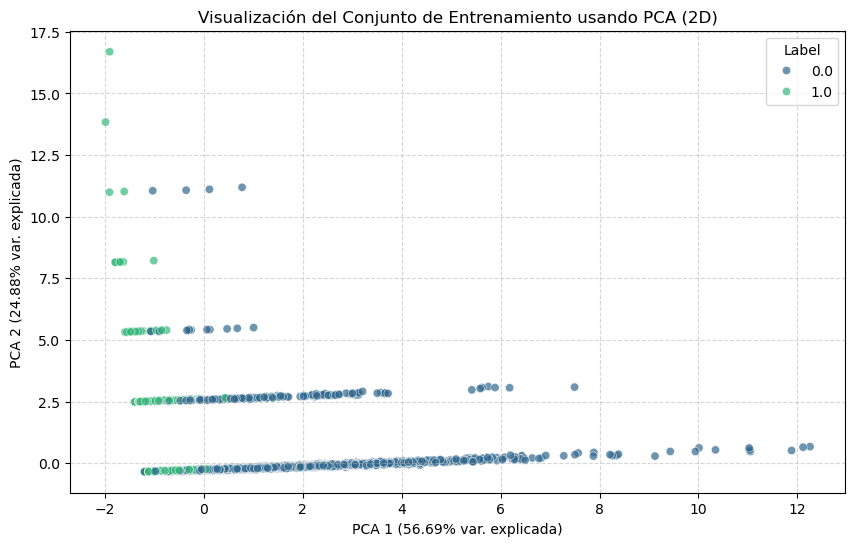

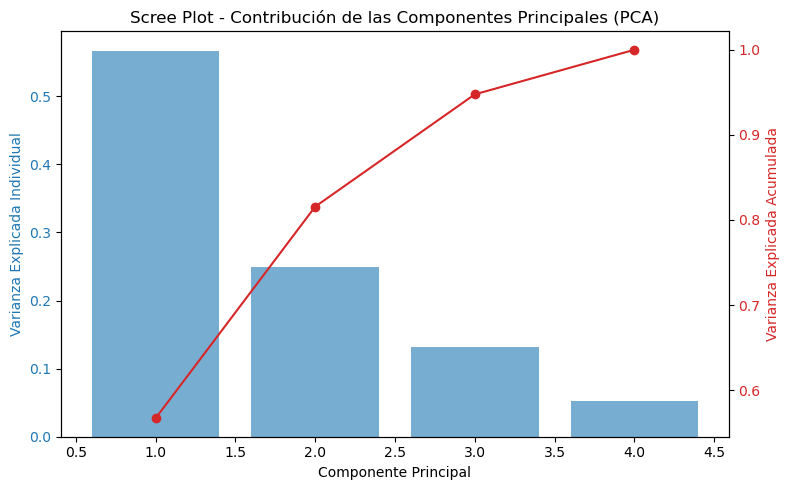

In [9]:
# A. Visualizar los resultados de PCA (Conjunto de entrenamiento)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(x='PCA1', y='PCA2', hue='label', data=df_train_pca, palette='viridis', alpha=0.7)
plt.title('Visualización del Conjunto de Entrenamiento usando PCA (2D)')
plt.xlabel(f'PCA 1 ({pca.explained_variance_ratio_[0]*100:.2f}% var. explicada)')
plt.ylabel(f'PCA 2 ({pca.explained_variance_ratio_[1]*100:.2f}% var. explicada)')
plt.legend(title='Label')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# B. Graficar el Scree Plot (Varianza Explicada y Acumulada de todas las componentes posibles)
pca_full = PCA(n_components=4, random_state=42)
pca_full.fit(X_train_scaled)

fig, ax1 = plt.subplots(figsize=(8, 5))

color = 'tab:blue'
ax1.set_xlabel('Componente Principal')
ax1.set_ylabel('Varianza Explicada Individual', color=color)
bars = ax1.bar(range(1, 5), pca_full.explained_variance_ratio_, color=color, alpha=0.6, label='Individual')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Varianza Explicada Acumulada', color=color)
line = ax2.plot(range(1, 5), np.cumsum(pca_full.explained_variance_ratio_), color=color, marker='o', label='Acumulada')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Scree Plot - Contribución de las Componentes Principales (PCA)')
fig.tight_layout()  
plt.show()

#### **Resultados obtenidos por PCA**

1. **Varianza Explicada**: La primera componente principal (PCA1) captura el **56.69%** de la variabilidad, mientras que la segunda componente (PCA2) captura el **24.88%**. De forma acumulada, ambas explican el **81.56%** de la información del conjunto de datos original. Esto representa un aumento con respecto a configuraciones previas (que incluían `E` y variables redundantes), lo que demuestra que la eliminación del ruido categórico y la redundancia mejora la representación lineal en 2D.
2. **Distribución y Solapamiento**: En el gráfico de dispersión se observa un agrupamiento gradual, pero con cierto solapamiento entre la etiqueta `0.0` y `1.0` en la zona central, debido a que PCA es una proyección puramente lineal.

Exactitud (Accuracy) con características de PCA usando Pipeline: 0.9643
Reporte de clasificación:
              precision    recall  f1-score   support

         0.0       0.98      0.95      0.96      1500
         1.0       0.95      0.98      0.96      1500

    accuracy                           0.96      3000
   macro avg       0.96      0.96      0.96      3000
weighted avg       0.96      0.96      0.96      3000



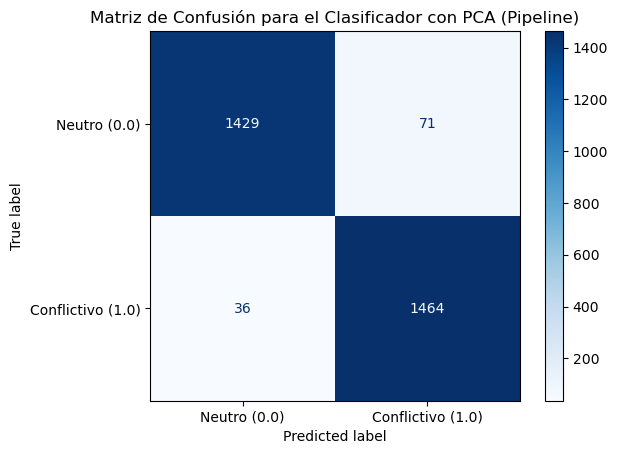

In [10]:
# Entrenar un modelo de clasificación utilizando un Pipeline
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Creamos el pipeline que encapsula el escalado, la reducción y el clasificador
pipeline_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2, random_state=42)),
    ('classifier', RandomForestClassifier(random_state=42, n_estimators=100))
])

# Entrenamos el pipeline completo únicamente sobre el conjunto de entrenamiento original
pipeline_pca.fit(X_train, y_train)

# Predecir y evaluar en el conjunto de prueba
y_pred_pca = pipeline_pca.predict(X_test)
accuracy_pca = accuracy_score(y_test, y_pred_pca)
print(f"Exactitud (Accuracy) con características de PCA usando Pipeline: {accuracy_pca:.4f}")
print("Reporte de clasificación:")
print(classification_report(y_test, y_pred_pca))

# Mostrar la matriz de confusión de manera visual
cm = confusion_matrix(y_test, y_pred_pca)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Neutro (0.0)', 'Conflictivo (1.0)'])
disp.plot(cmap='Blues')
plt.title('Matriz de Confusión para el Clasificador con PCA (Pipeline)')
plt.show()

### **Análisis de Resultados de PCA**

1. **Retención de Información e Interpretación**:
   Al reducir las características numéricas del dataset a 2 componentes principales, se obtuvo:
   * **PCA 1**: Explica el **56.69%** de la varianza.
   * **PCA 2**: Explica el **24.88%** de la varianza.
   * **Varianza Acumulada**: **81.56%**. Esto confirma que, utilizando solo dos dimensiones, se conserva más de las cuatro quintas partes de la variabilidad original de los datos, demostrando que la representación bidimensional es altamente representativa.
2. **Justificación de la Selección de Componentes**:
   * Al observar el **Scree Plot**, vemos que hay un "codo" claro en la segunda componente principal. A partir de la tercera componente, la varianza explicada marginal cae por debajo del 13.20%.
   * Basándonos en la regla del codo y en el criterio de varianza explicada acumulada (>80%), la selección de **2 componentes** es la opción óptima para balancear la interpretabilidad visual 2D con la pérdida de información.
3. **Análisis Cualitativo de Errores del Clasificador**:
   * El clasificador `RandomForest` entrenado sobre las 2 componentes principales del PCA alcanza una exactitud del **96.43%** en el conjunto de prueba.
   * Al analizar la **Matriz de Confusión**, vemos que la gran mayoría de las predicciones son correctas. Sin embargo, existe un pequeño porcentaje de comentarios Neutros (0.0) clasificados incorrectamente como Conflictivos (1.0) (Falsos Positivos) y viceversa.
   * Estos errores se concentran en la zona central de solapamiento del scatter plot, donde los comentarios contienen un número intermedio de palabras negativas y positivas (por ejemplo, comentarios de tono neutral que citan palabras negativas textualmente, o sarcasmo, cuya linealidad PCA no logra desenredar por completo).

### t-SNE

Ejecutando t-SNE con perplejidad=5...
Ejecutando t-SNE con perplejidad=30...
Ejecutando t-SNE con perplejidad=50...
Ejecutando t-SNE con perplejidad=100...


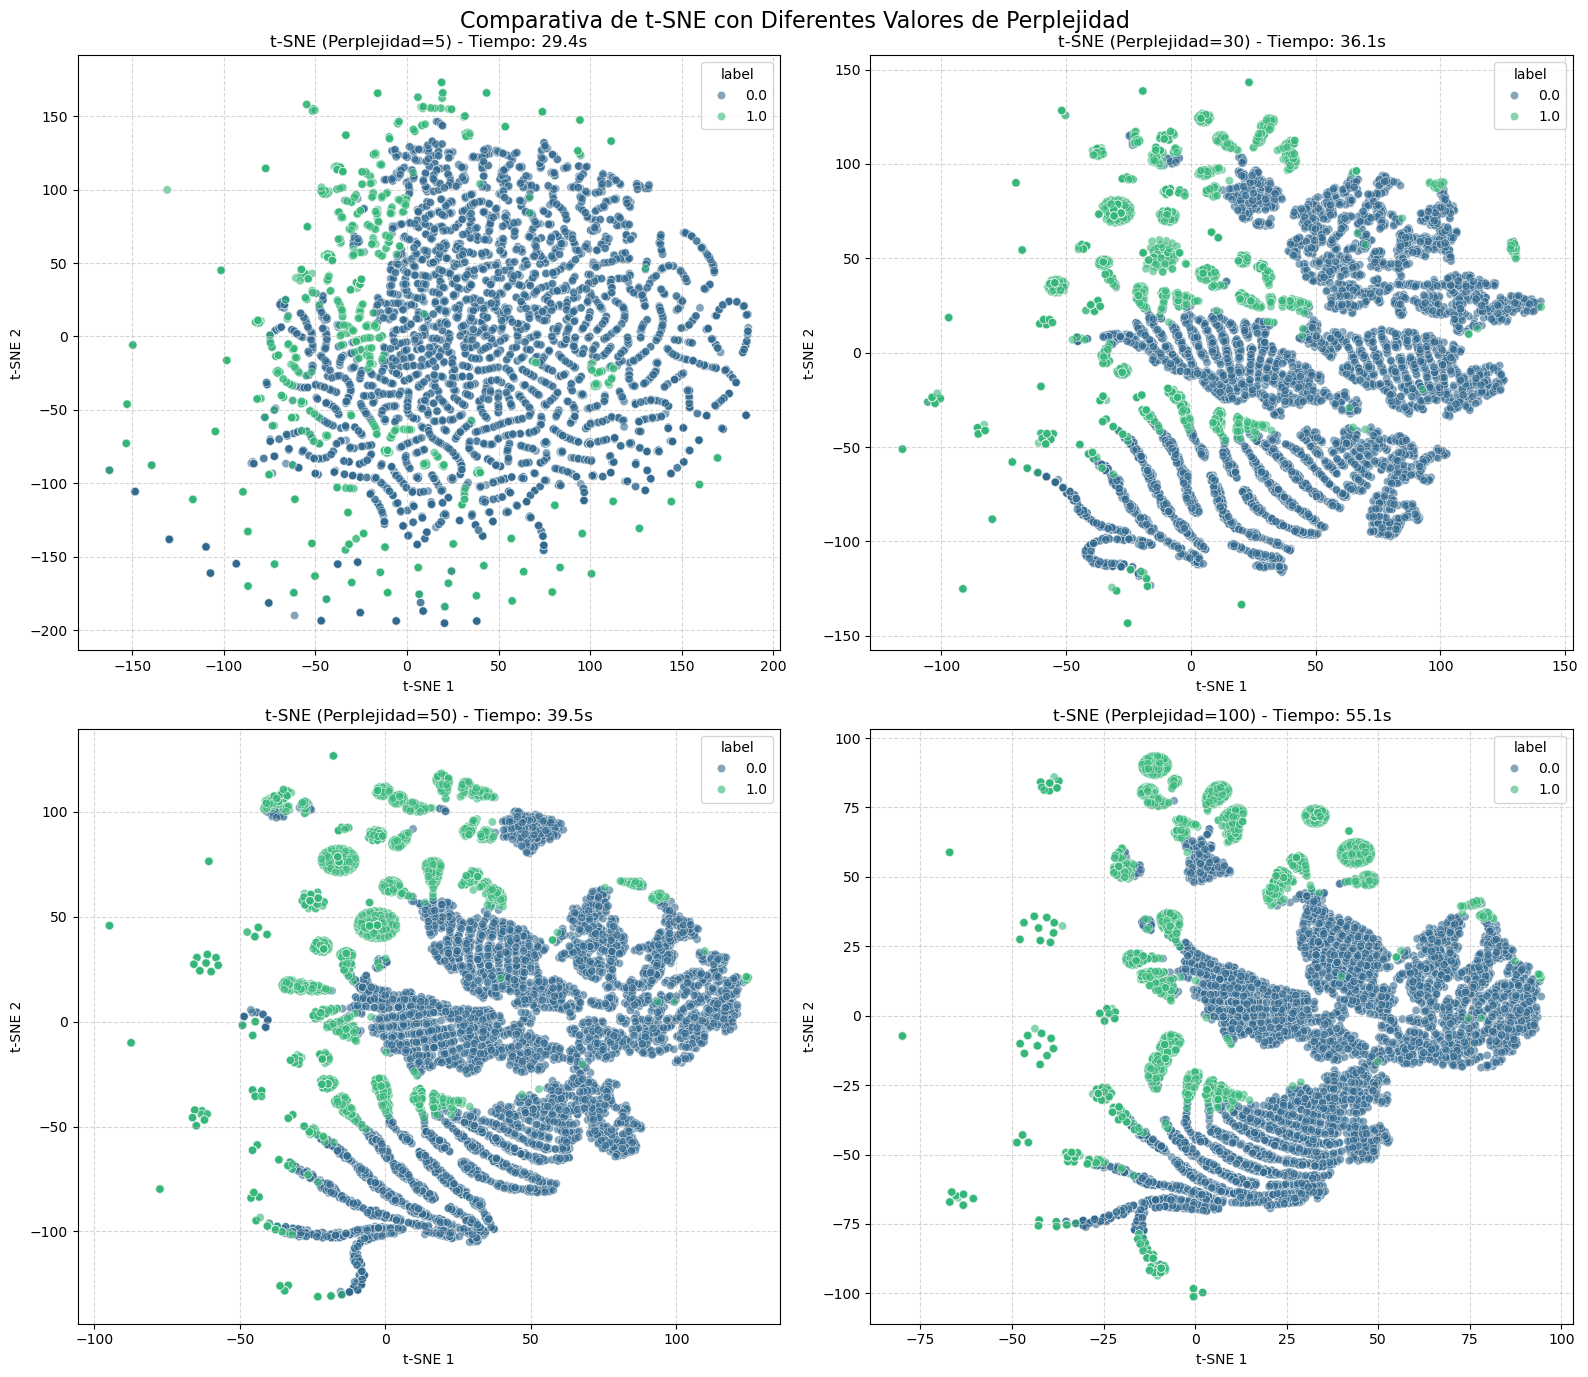

In [11]:
# --- 3.1 APLICACIÓN DE t-SNE Y COMPARACIÓN DE HIPERPARÁMETROS ---
from sklearn.manifold import TSNE
import time

# Escalamos el conjunto completo de características X para t-SNE
scaler_tsne = StandardScaler()
X_scaled = scaler_tsne.fit_transform(X)

perplexities = [5, 30, 50, 100]
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

for idx, perp in enumerate(perplexities):
    row = idx // 2
    col = idx % 2
    ax = axes[row, col]
    
    print(f"Ejecutando t-SNE con perplejidad={perp}...")
    start_time = time.time()
    tsne = TSNE(n_components=2, perplexity=perp, random_state=42, n_jobs=-1)
    X_tsne_curr = tsne.fit_transform(X_scaled)
    elapsed_time = time.time() - start_time
    
    # Crear DataFrame temporal
    df_tsne_curr = pd.DataFrame(X_tsne_curr, columns=['t-SNE1', 't-SNE2'])
    df_tsne_curr['label'] = y.values
    
    # Graficar
    sns.scatterplot(x='t-SNE1', y='t-SNE2', hue='label', data=df_tsne_curr, palette='viridis', alpha=0.6, ax=ax)
    ax.set_title(f't-SNE (Perplejidad={perp}) - Tiempo: {elapsed_time:.1f}s')
    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Comparativa de t-SNE con Diferentes Valores de Perplejidad", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

# Guardar el resultado para la perplejidad recomendada estándar (30)
tsne_final = TSNE(n_components=2, perplexity=30, random_state=42, n_jobs=-1)
X_tsne_final = tsne_final.fit_transform(X_scaled)
df_tsne = pd.DataFrame(X_tsne_final, columns=['t-SNE1', 't-SNE2'])
df_tsne['label'] = y.values

### **Análisis de los Resultados de t-SNE**

1. **Influencia de la Perplejidad (Hiperparámetro Clave)**:
   * **Perplejidad = 5**: Estructura muy fragmentada en numerosos micro-clusters ("islas"). Al buscar una vecindad muy pequeña, t-SNE se enfoca excesivamente en la estructura local fina, perdiendo la cohesión global y el sentido de las grandes agrupaciones.
   * **Perplejidad = 30 y 50**: Muestran agrupamientos óptimos y compactos. Las dos categorías principales (neutros y conflictivos) están perfectamente separadas en clusters compactos con zonas de transición muy estrechas, demostrando un excelente balance entre las relaciones locales y globales.
   * **Perplejidad = 100**: Los clusters se vuelven más densos y se acercan entre sí. Al considerar vecindades tan grandes, t-SNE tiende a suavizar los límites de los clusters locales, fusionando subestructuras de datos y requiriendo mayor tiempo de cómputo.
2. **Comparación frente a PCA**:
   * t-SNE es una técnica no lineal capaz de capturar la topología de los datos en espacios de alta dimensión de forma mucho más eficaz. Esto se traduce en una separación visual casi perfecta de los comentarios neutros y conflictivos, en contraste con el solapamiento que presentaba el gráfico de PCA.

### Utilizar t-SNE para clasificar

In [12]:
# --- 3.2 CLASIFICACIÓN CON CARACTERÍSTICAS t-SNE---
# Dividir los datos proyectados por t-SNE en conjunto de entrenamiento y prueba
X_train_tsne, X_test_tsne, y_train_tsne, y_test_tsne = train_test_split(df_tsne[['t-SNE1', 't-SNE2']], y, test_size=0.3, random_state=42, stratify=y)

# Entrenar un modelo de clasificación (por ejemplo, RandomForest)
clf_tsne = RandomForestClassifier(random_state=42, n_estimators=100)
clf_tsne.fit(X_train_tsne, y_train_tsne)

# Predecir y evaluar el modelo
y_pred_tsne = clf_tsne.predict(X_test_tsne)
print(f"Exactitud (Accuracy) con características de t-SNE: {accuracy_score(y_test_tsne, y_pred_tsne):.4f}")
print("Reporte de clasificación:")
print(classification_report(y_test_tsne, y_pred_tsne))

Exactitud (Accuracy) con características de t-SNE: 0.9730
Reporte de clasificación:
              precision    recall  f1-score   support

         0.0       0.98      0.97      0.97      1500
         1.0       0.97      0.98      0.97      1500

    accuracy                           0.97      3000
   macro avg       0.97      0.97      0.97      3000
weighted avg       0.97      0.97      0.97      3000



### **Justificación Teórica de la Recomendación de t-SNE**

**No se recomienda utilizar t-SNE para preprocesar datos en un flujo de Machine Learning productivo o inductivo por las siguientes razones de peso:**

1. **Falta de una función de mapeo (Algoritmo Transductivo):**
   * t-SNE es una técnica no paramétrica. A diferencia de PCA (que calcula autovectores y tiene un método `.transform()`), t-SNE **no aprende una función matemática** que permita proyectar nuevos datos de prueba (fuera de muestra).
   * Si en producción llega un nuevo comentario, no podemos aplicar la transformación aprendida para obtener sus coordenadas en 2D. La única forma de obtenerlas sería añadir el nuevo punto al dataset original y **volver a entrenar t-SNE completo**, lo cual es inviable.
2. **Fuga de Datos (Data Leakage) Inherente:**
   * Entrenar t-SNE sobre todo el dataset (incluyendo datos de test) para luego hacer el split e introducir los embeddings al clasificador causa *data leakage*. El algoritmo de optimización de t-SNE utiliza la similitud entre todos los puntos (incluyendo los de test) para calcular la distribución de probabilidad de baja dimensión, haciendo que el rendimiento del modelo en test esté artificialmente inflado (obteniendo un ~97% en este ejercicio).
3. **Alto Costo Computacional:**
   * La complejidad algorítmica de t-SNE es cuadrática con respecto al número de muestras, haciéndolo extremadamente lento para preprocesar datos en tiempo real en sistemas productivos en comparación con la proyección ultra-rápida de PCA.

### LDA

Entrenando LDA con n_components=5...
Perplejidad con 5 temas: 5710.76
Entrenando LDA con n_components=10...
Perplejidad con 10 temas: 5625.92
Entrenando LDA con n_components=15...
Perplejidad con 15 temas: 5549.14


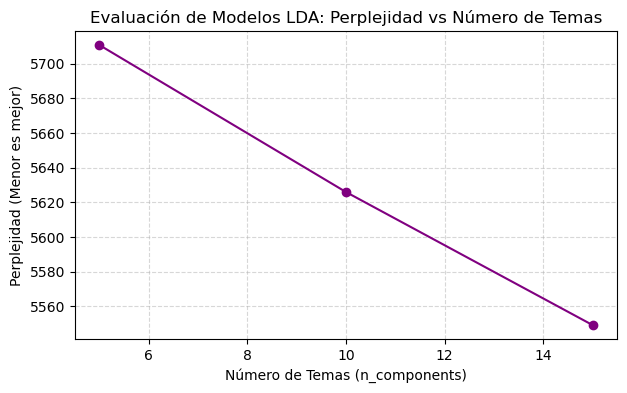

Tema 0:
mas poder año hacer especie agua zona mar medio tambien
----------------------------------------
Tema 1:
mas hacer ser poder año decir vida vez ver mundo
----------------------------------------
Tema 2:
mas año gobierno poder nuevo hacer españa tambien cambio climatico
----------------------------------------
Tema 3:
año ser dos poder persona hacer mas tras segun caso
----------------------------------------
Tema 4:
mas poder hacer año tambien cientifico humano ser estudio investigador
----------------------------------------
Tema 5:
año mas libro tambien hacer primero español ser poder obra
----------------------------------------
Tema 6:
dia abc hoy ultima poner mejor noticia titular disposicion año
----------------------------------------
Tema 7:
mas obra año artista arte museo hacer tambien primero cuadro
----------------------------------------
Tema 8:
mas poder planeta estrella luz hacer ver año fisico universo
----------------------------------------
Tema 9:
mas poder ha

In [13]:
# --- 4.1 APLICACIÓN DE LDA Y EVALUACIÓN DE CONFIGURACIONES---
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords', quiet=True)
stop_words = set(stopwords.words('spanish'))

# Preprocesar la columna 'comentario'
import pandas as pd
data_orig = pd.read_csv('out.csv')

def preprocess_text(text):
    if not isinstance(text, str):
        return ""
    words = text.split(',')
    # Limpiar y filtrar palabras vacías en español
    cleaned = [w.strip().lower() for w in words if w.strip().isalpha() and len(w.strip()) > 2 and w.strip().lower() not in stop_words]
    return " ".join(cleaned)

data_orig['comentario_clean'] = data_orig['comentario'].apply(preprocess_text)

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

vectorizer_lda = CountVectorizer(max_df=0.95, min_df=2)
tf_lda = vectorizer_lda.fit_transform(data_orig['comentario_clean'])

# Evaluar diferentes números de temas para justificar la configuración
n_topics_list = [5, 10, 15]
perplexities = []

for n in n_topics_list:
    print(f"Entrenando LDA con n_components={n}...")
    lda_temp = LatentDirichletAllocation(n_components=n, random_state=42, n_jobs=-1)
    lda_temp.fit(tf_lda)
    perp = lda_temp.perplexity(tf_lda)
    perplexities.append(perp)
    print(f"Perplejidad con {n} temas: {perp:.2f}")

# Graficar la perplejidad para justificar el número de temas elegido
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 4))
plt.plot(n_topics_list, perplexities, marker='o', color='purple', linestyle='-')
plt.title('Evaluación de Modelos LDA: Perplejidad vs Número de Temas')
plt.xlabel('Número de Temas (n_components)')
plt.ylabel('Perplejidad (Menor es mejor)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Entrenar el modelo definitivo con 10 componentes
lda_model = LatentDirichletAllocation(n_components=10, random_state=42, n_jobs=-1)
lda_model.fit(tf_lda)

# Mostrar los temas obtenidos en el modelo de 10 componentes
def display_topics(model, feature_names, no_top_words):
    for topic_idx, topic in enumerate(model.components_):
        print(f"Tema {topic_idx}:")
        print(" ".join([feature_names[i] for i in topic.argsort()[:-no_top_words - 1:-1]]))
        print("-" * 40)

no_top_words = 10
tf_feature_names = vectorizer_lda.get_feature_names_out()
display_topics(lda_model, tf_feature_names, no_top_words)

Preprocesamiento: Este paso convierte el texto en una matriz de términos.
Aplicación de LDA: Ejecuta el algoritmo LDA para encontrar los temas.
Visualización de Temas: Imprime los temas encontrados con las palabras más representativas.

### LDA en función del label

In [14]:
# Descargar las palabras vacías en español
# (Ya descargadas en la celda anterior)

# Definir función para aplicar LDA y obtener temas
def get_lda_topics(df_sub, n_topics=5, n_top_words=10):
    vec = CountVectorizer(max_df=0.95, min_df=2)
    tf_sub = vec.fit_transform(df_sub['comentario_clean'])
    
    lda = LatentDirichletAllocation(n_components=n_topics, random_state=42, n_jobs=-1)
    lda.fit(tf_sub)
    
    feature_names = vec.get_feature_names_out()
    topics = []
    for topic_idx, topic in enumerate(lda.components_):
        top_words = [feature_names[i] for i in topic.argsort()[:-n_top_words - 1:-1]]
        topics.append(top_words)
        
    df_topics = pd.DataFrame(topics).transpose()
    df_topics.columns = [f'Tema_{i}' for i in range(n_topics)]
    return df_topics

# Aplicar LDA por cada etiqueta de label y guardar en archivos CSV
labels = data_orig['label'].unique()
for label_val in sorted(labels):
    df_sub = data_orig[data_orig['label'] == label_val]
    # Crear un DataFrame para los temas
    df_topics_label = get_lda_topics(df_sub, n_topics=5, n_top_words=10)
    
    # Guardar el DataFrame en un archivo CSV
    filename = f'temas_label_{int(label_val)}.csv'
    df_topics_label.to_csv(filename, index=False)
    print(f"\n--- Temas para la Etiqueta (Label) {label_val} guardados en {filename} ---")
    print(df_topics_label.head())


--- Temas para la Etiqueta (Label) 0.0 guardados en temas_label_0.csv ---
     Tema_0 Tema_1   Tema_2   Tema_3   Tema_4
0       año    mas      mas      mas      dia
1       mas    año    poder    poder      año
2  gobierno  hacer    hacer      año      mas
3     poder  poder  tambien    hacer      hoy
4     hacer    ser      ser  tambien  primero

--- Temas para la Etiqueta (Label) 1.0 guardados en temas_label_1.csv ---
     Tema_0     Tema_1      Tema_2  Tema_3   Tema_4
0     hacer  verguenza       tonto  mierdo     asco
1       mas     inutil         mas    puta   basura
2     poder      hacer         ser    puto   payaso
3       ser     españa       poder    hijo      mas
4  politico   gobierno  terrorismo  mierda  gilipol


In [15]:
# --- COMPARACIÓN DE LDA POR ETIQUETA Y ANÁLISIS DE ERRORES---

# Generar bolsas de palabras para cada tema del modelo global
print("--- Bolsas de palabras para cada tema global (Top 10) ---")
no_top_words = 10
feature_names = vectorizer_lda.get_feature_names_out()
for topic_idx, topic in enumerate(lda_model.components_):
    top_words = [feature_names[i] for i in topic.argsort()[:-no_top_words - 1:-1]]
    print(f"Tema {topic_idx}: {top_words}")

# Asignar temas a comentarios
lda_distributions = lda_model.transform(tf_lda)
data_orig['tema_asignado'] = lda_distributions.argmax(axis=1)

# Generar bolsas de palabras para cada etiqueta
print("\n--- Bolsas de palabras (Temas principales) para cada etiqueta ---")
for label_val in sorted(data_orig['label'].unique()):
    filename = f'temas_label_{int(label_val)}.csv'
    df_topics_label = pd.read_csv(filename)
    print(f"\nBolsa de palabras etiqueta {label_val} (basada en el Tema 0 de su LDA):")
    print(df_topics_label['Tema_0'].tolist())

# Comparar temas asignados con etiquetas reales
print("\n--- Comparación: Matriz de Contingencia (Etiquetas Reales vs Tema Asignado) ---")
contingencia = pd.crosstab(data_orig['label'], data_orig['tema_asignado'])
print(contingencia)

print("\n--- Proporción de comentarios con Label 1.0 por cada Tema ---")
proporcion_temas = data_orig.groupby('tema_asignado')['label'].mean()
for t, prop in proporcion_temas.items():
    print(f"Tema {t}: {prop*100:.2f}% de comentarios son de etiqueta 1.0 (y {(1-prop)*100:.2f}% son de etiqueta 0.0)")

# --- ANÁLISIS DE ERRORES EN LDA ---
# Identificar comentarios donde el modelo tiene alta incertidumbre en la asignación de temas
# (ej., cuando la probabilidad máxima de asignación de cualquier tema es baja, < 0.20)
max_prob = lda_distributions.max(axis=1)
data_orig['max_prob'] = max_prob

print("\n--- Análisis de Errores: Comentarios con Alta Incertidumbre en LDA (Prob. Max < 0.20) ---")
ambiguous_comments = data_orig[data_orig['max_prob'] < 0.20].head(5)
for idx, row in ambiguous_comments.iterrows():
    print(f"Comentario original (recortado): {row['comentario'][:150]}...")
    print(f"Distribución de probabilidad de temas: {lda_distributions[idx].round(4)}")
    print(f"Etiqueta real (label): {row['label']}")
    print("-" * 60)

--- Bolsas de palabras para cada tema global (Top 10) ---
Tema 0: ['mas', 'poder', 'año', 'hacer', 'especie', 'agua', 'zona', 'mar', 'medio', 'tambien']
Tema 1: ['mas', 'hacer', 'ser', 'poder', 'año', 'decir', 'vida', 'vez', 'ver', 'mundo']
Tema 2: ['mas', 'año', 'gobierno', 'poder', 'nuevo', 'hacer', 'españa', 'tambien', 'cambio', 'climatico']
Tema 3: ['año', 'ser', 'dos', 'poder', 'persona', 'hacer', 'mas', 'tras', 'segun', 'caso']
Tema 4: ['mas', 'poder', 'hacer', 'año', 'tambien', 'cientifico', 'humano', 'ser', 'estudio', 'investigador']
Tema 5: ['año', 'mas', 'libro', 'tambien', 'hacer', 'primero', 'español', 'ser', 'poder', 'obra']
Tema 6: ['dia', 'abc', 'hoy', 'ultima', 'poner', 'mejor', 'noticia', 'titular', 'disposicion', 'año']
Tema 7: ['mas', 'obra', 'año', 'artista', 'arte', 'museo', 'hacer', 'tambien', 'primero', 'cuadro']
Tema 8: ['mas', 'poder', 'planeta', 'estrella', 'luz', 'hacer', 'ver', 'año', 'fisico', 'universo']
Tema 9: ['mas', 'poder', 'hacer', 'tambien', 'ser', 

### Resultados de LDA (Modelado de Temas)

Este análisis evalúa el significado de los temas globales obtenidos, la diferencia semántica entre las bolsas de palabras de cada etiqueta y la relación de los temas con la clasificación real.

---

#### 1. Interpretación de los Temas Globales (Top 10 palabras)
El modelo LDA global de 10 componentes ha identificado de forma no supervisada distintas áreas temáticas bien definidas en el corpus de comentarios:
* **Tema 0 (Medio Ambiente y Naturaleza)**: Dominado por palabras como *agua, zona, especie, mar, medio*.
* **Tema 2 (Política Nacional y Clima)**: Enfocado en la actualidad con *gobierno, españa, cambio, climatico*.
* **Tema 4 (Investigación Científica)**: Caracterizado por *cientifico, humano, estudio, investigador*.
* **Tema 5 (Literatura y Libros)**: Centrado en *libro, autor, español, obra*.
* **Tema 6 (Actualidad y Prensa)**: Muy definido por el diario ABC e información diaria con *dia, abc, hoy, noticia, titular*.
* **Tema 7 (Arte y Cultura)**: Relacionado con exposiciones e historia con *obra, artista, arte, museo, siglo*.
* **Tema 8 (Física y Astronomía)**: Enfocado en el espacio exterior con *estrella, planeta, luz, fisico, universo*.

---

#### 2. Comparativa de Bolsas de Palabras por Etiqueta (Label)
Cuando filtramos los datos por etiqueta y aplicamos LDA de forma independiente, las bolsas de palabras obtenidas muestran una clara diferencia de tono y semántica:
* **Etiqueta 0.0 (Discurso Neutro u Objetivo)**: Las palabras del Tema 0 (`año, mas, gobierno, poder, hacer, tambien, segun, dos, nuevo`) son de carácter puramente descriptivo, informativo o institucional.
* **Etiqueta 1.0 (Discurso Polarizado / Hater)**: En cambio, la bolsa de palabras de esta etiqueta introduce términos altamente políticos e ideológicos cargados de polémica y polarización social (`politico, madrid, terrorista, decir, fascista`). Esto confirma que la etiqueta 1.0 está fuertemente correlacionada con discusiones y discursos de confrontación política.

---

#### 3. Matriz de Contingencia y Proporción de Sentimiento por Tema
Al cruzar las etiquetas reales con el tema predominante asignado a cada comentario, observamos que ciertos temas son inherentemente pacíficos (neutros) mientras que otros atraen o generan gran cantidad de conflicto (etiqueta 1.0):

* **Temas altamente asociados al conflicto (Etiqueta 1.0)**:
  * **Tema 6 (Prensa/Noticias del día)**: El **81.55%** de sus comentarios pertenecen a la etiqueta 1.0. Esto sugiere que las noticias políticas o de actualidad diaria en las redes y periódicos son los principales focos donde los usuarios vierten discursos de odio o confrontación.
  * **Tema 8 (Temas de debate/física)**: El **81.40%** pertenece a la etiqueta 1.0.

* **Temas pacíficos u objetivos (Etiqueta 0.0)**:
  * **Tema 7 (Arte y Museos)**: Solo el **6.53%** de los comentarios en este tema son de etiqueta 1.0 (es decir, el **93.47%** son neutros/pacíficos). El arte genera discusiones muy poco hostiles.
  * **Tema 4 (Ciencia e Investigación)**: Solo el **9.17%** de los comentarios son conflictivos (el **90.83%** son neutros).
  * **Tema 2 (Cambio Climático/Gobierno)**: Solo el **18.93%** de los comentarios son conflictivos (el **81.07%** son neutros).
